In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import Path
from matplotlib.ticker import PercentFormatter
import seaborn as sns


pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_rows", 200)
pd.set_option("display.max_columns", None)


style_colors = {
    "modernizm": "#3F71C4",
    "współczesność": "#FFAD37",
    "klasycyzm": "#42A600",
    "tradycjonalizm": "#FFF921",
    "postmodernizm": "#FF85F7",
}

column_types = {
    "id": "Int64",
    "osm_id": "str",
    "addr_street": "str",
    "addr_number": "str",
    "ground_floor_group": "str",
    "ground_floor_function": "str",
    "upper_floor_group": "str",
    "upper_floor_function": "str",
    "number_of_storeys": "Int64",
    "is_mixed_use": "boolean",
    "build_year_est": "Int64",
    "arch_style": "str",
    "condition": "Int64",
    "max_height": "float64",
    "is_heritage": "str",
    "source": "str",
    "confidence": "Int64",
    "date_of_checking": "str",
}

In [2]:
data_gdynia = pd.read_csv(
    "../data/processed/fixed/srodmiescie.csv",
    sep=";",
    index_col=0,
    dtype=column_types,
    parse_dates=["date_of_checking"],
)
data_gdynia

,osm_id,addr_street,addr_number,ground_floor_group,ground_floor_function,upper_floor_group,upper_floor_function,number_of_storeys,is_mixed_use,build_year_est,arch_style,condition,max_height,is_heritage,source,confidence,date_of_checking,number_of_functions
id,,,,,,,,,,,,,,,,,,
1,127184291,Świętego Piotra,8,NaN,hotel,NaN,Hotel,7,<NA>,2000,współczesność,3,NaN,NaN,google.com/maps,3,2026-09-27,1
2,890729731,Świętego Piotra,6D,NaN,mieszkaniowa wielorodzinna,NaN,Mieszkaniowa Wielorodzinna,5,<NA>,2020,współczesność,3,NaN,NaN,google.com/maps,3,2026-09-27,1
3,890292040,Węglowa,22,NaN,centrum handlowe,NaN,Mieszkaniowa Wielorodzinna,17,<NA>,2020,współczesność,3,NaN,NaN,google.com/maps,3,2026-09-27,1
4,890729732,Świętego Piotra,6,NaN,mieszkaniowa wielorodzinna,NaN,Mieszkaniowa Wielorodzinna,17,<NA>,2020,współczesność,3,NaN,NaN,google.com/maps,3,2026-09-27,1
5,136885205,Tadeusza Wendy,15,NaN,centrum medyczne,NaN,Centrum Medyczne,6,<NA>,2000,współczesność,3,NaN,NaN,google.com/maps,2,2026-09-27,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1237,126180359,Władysława IV,61,NaN,"laboratorium medyczne,piekarnia,kiosk",NaN,Mieszkaniowa Wielorodzinna,7,<NA>,1940,modernizm,3,NaN,NaN,google.com/maps,2,2026-09-30,3
1238,126173503,Świętojańska,122,NaN,"apteka,handel zdrowie",NaN,Biurowa,6,<NA>,1930,modernizm,2,NaN,NaN,google.com/maps,2,2026-09-30,2
1239,260676369,Aleja Marszałka Józefa Piłsudskiego,56,NaN,mieszkaniowa wielorodzinna,NaN,Mieszkaniowa Wielorodzinna,7,<NA>,1930,modernizm,2,NaN,NaN,google.com/maps,2,2026-09-30,1


In [3]:
data_gdynia_long = pd.read_csv(
    "../data/processed/fixed/srodmiescie_long.csv",
    sep=";",
    index_col=0,
    dtype=column_types,
)
data_gdynia_long.head()

,addr_street,ground_floor_function
id,,
1,Świętego Piotra,hotel
2,Świętego Piotra,mieszkaniowa wielorodzinna
3,Węglowa,centrum handlowe
4,Świętego Piotra,mieszkaniowa wielorodzinna
5,Tadeusza Wendy,centrum medyczne


1.

In [4]:
build_per_style = (
    data_gdynia.groupby("arch_style").agg("size").sort_values(ascending=False)
)

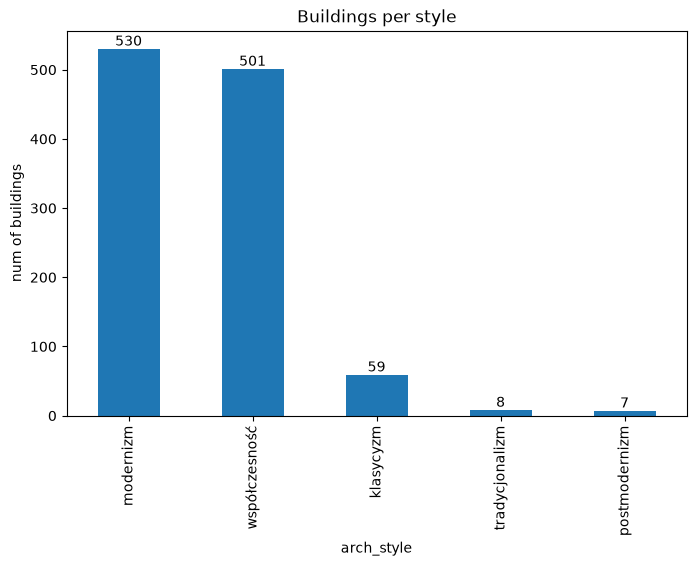

In [5]:
fig1, ax1 = plt.subplots(figsize=(8, 5))

build_per_style.plot.bar(ax=ax1)

ax1.set_title("Buildings per style")
ax1.set_ylabel("num of buildings")
ax1.set_xlabel("arch_style")
ax1.bar_label(ax1.containers[0])

plt.show()

In [6]:
assert len(ax1.patches) == len(build_per_style)

# height = [p.get_height() for p in ax1.patches]
height = []
for p in ax1.patches:
    height.append(p.get_height())

assert height == build_per_style.tolist()


2.

In [7]:
def only_big_streets(df, min_build):
    return df.loc[df.groupby("addr_street").transform("size") >= min_build]


build_num_streets = (
    data_gdynia.pipe(only_big_streets, min_build=20)
    .groupby("addr_street")
    .agg("size")
    .sort_values(ascending=True)
)

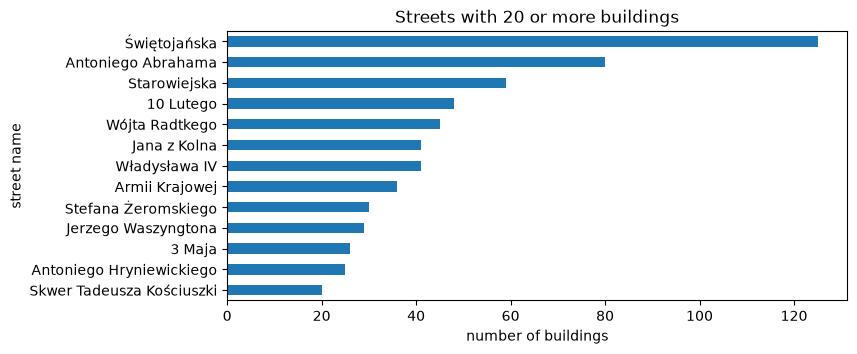

In [8]:
fig2, ax2 = plt.subplots(figsize=(8, 3.5))

build_num_streets.plot.barh(ax=ax2)

ax2.set_title("Streets with 20 or more buildings")
ax2.set_xlabel("number of buildings")
ax2.set_ylabel("street name")

plt.show()

In [9]:
assert len(ax2.patches) == len(build_num_streets)
width = [p.get_width() for p in ax2.patches]
assert width == build_num_streets.tolist()

3.

In [10]:
num_storeys = data_gdynia["number_of_storeys"].value_counts().sort_index()
num_storeys

number_of_storeys
1     426
2      74
3      42
4      43
5     161
6     242
7      58
8      14
9      16
10     11
11     11
12      3
13      1
17      2
38      1
Name: count, dtype: Int64

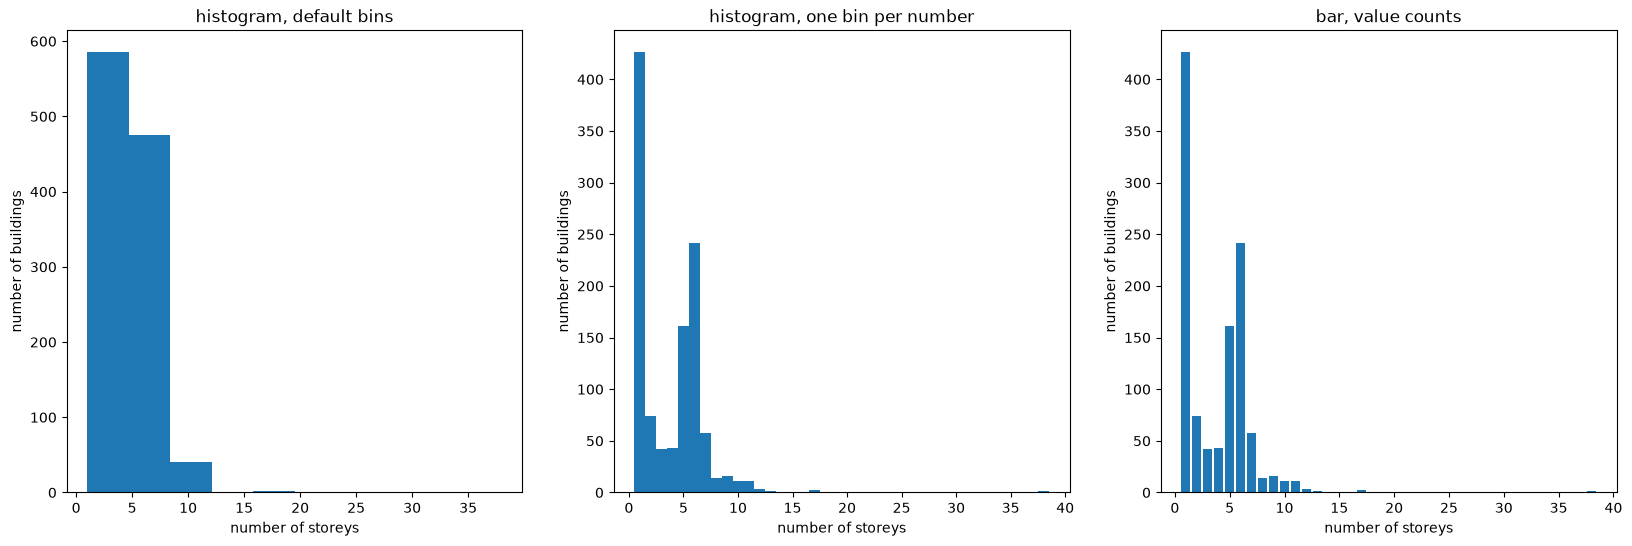

In [11]:
fig3, ax3 = plt.subplots(1, 3, figsize=(20, 6))

ax3[0].hist(data_gdynia["number_of_storeys"])
ax3[1].hist(data_gdynia["number_of_storeys"], bins=np.arange(0.5, 39.5))
ax3[2].bar(num_storeys.index, num_storeys.values)


ax3[0].set_title("histogram, default bins")
ax3[1].set_title("histogram, one bin per number")
ax3[2].set_title("bar, value counts")

for ax in ax3:
    ax.set_xlabel("number of storeys")

for ax in ax3:
    ax.set_ylabel("number of buildings")

plt.show()

In [12]:
height2 = []
for p in ax3[1].patches:
    height2.append(p.get_height())

assert sum(height2) == len(data_gdynia)
assert height2[0] == 426
assert height2[5] == 242
height2 = np.array(height2)
assert (height2[height2 > 0] == num_storeys.values).all()


height3 = []
for p in ax3[2].patches:
    height3.append(p.get_height())

height3 = np.array(height3)
assert np.array_equal(height3, num_storeys.to_list())

4.

In [13]:
top_styles = (
    data_gdynia.groupby("arch_style")
    .agg(num_buildings=("osm_id", "size"), median_cond=("number_of_storeys", "median"))
    .nlargest(2, "num_buildings")
)

bins = np.arange(0.5, data_gdynia["number_of_storeys"].max() + 1)

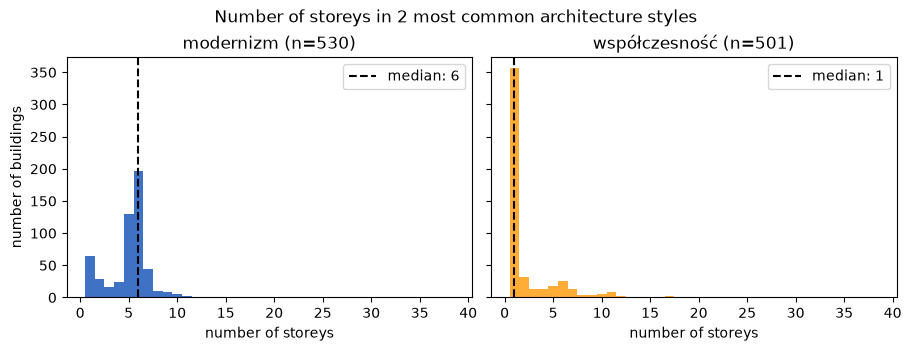

In [14]:
fig4, ax4 = plt.subplots(1, 2, figsize=(9, 3.4), sharey=True, layout="constrained")


for ax, style in zip(ax4, top_styles.index):
    storeys = data_gdynia.loc[data_gdynia["arch_style"] == style, "number_of_storeys"]
    median = top_styles.loc[style, "median_cond"]
    n = top_styles.loc[style, "num_buildings"]
    ax.hist(storeys, bins=bins, color=style_colors[style])
    ax.axvline(median, color="black", linestyle="--", label=f"median: {median:.0f}")
    ax.set(title=f"{style} (n={n})", xlabel="number of storeys")
    ax.legend()


ax4[0].set_ylabel("number of buildings")
fig4.suptitle("Number of storeys in 2 most common architecture styles")

plt.show()

In [15]:
# sprawdzenie
assert ax4[0].get_ylim() == ax4[1].get_ylim()

sums = [sum(p.get_height() for p in ax.patches) for ax in ax4]
assert sums == top_styles["num_buildings"].tolist()

5.

In [16]:
checked_per_day = data_gdynia.groupby("date_of_checking").agg("size")

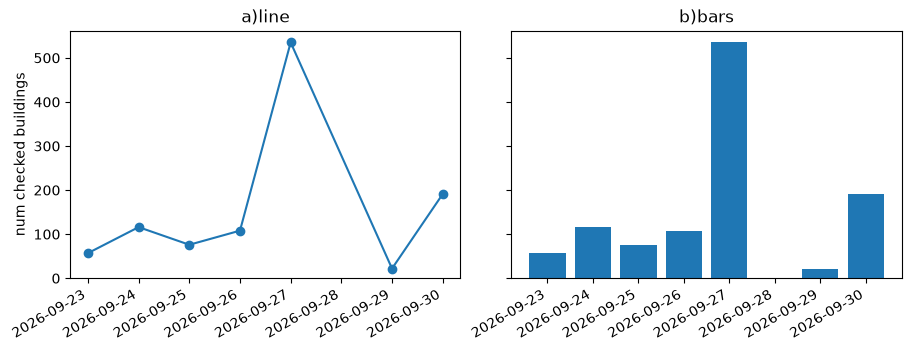

In [17]:
fig5, ax5 = plt.subplots(1, 2, figsize=(9, 3.4), sharey=True, layout="constrained")
fig5.autofmt_xdate()


ax5[0].plot(checked_per_day.index, checked_per_day.values, marker="o")
ax5[1].bar(checked_per_day.index, checked_per_day.values)

ax5[0].set_title("a)line")
ax5[1].set_title("b)bars")
ax5[0].set_ylabel("num checked buildings")

fig5.savefig("figures/checked_per_day.png", dpi=150, bbox_inches="tight")
plt.show()

In [18]:
assert Path("figures/checked_per_day.png").exists()
assert Path("figures/checked_per_day.png").stat().st_size > 0

height5 = []
for p in ax5[1].patches:
    height5.append(p.get_height())

assert len(height5) == data_gdynia["date_of_checking"].nunique()
assert len(ax5[0].lines[0].get_ydata()) == data_gdynia["date_of_checking"].nunique()

6.

In [19]:
build_num_streets_rank = (
    data_gdynia.pipe(only_big_streets, min_build=20)
    .groupby("addr_street")
    .agg(
        num_storeys_mean=("number_of_storeys", "mean"),
        num_buildings=("osm_id", "size"),
    )
    .assign(num_total_storeys=lambda d: d["num_storeys_mean"] * d["num_buildings"])
)
build_num_streets_rank["rank"] = build_num_streets_rank["num_storeys_mean"].rank(
    ascending=False, method="min"
)
build_num_streets_rank = build_num_streets_rank.sort_values(
    "num_storeys_mean", ascending=True
)

total_num_build6 = build_num_streets_rank["num_buildings"].sum()
mean6 = build_num_streets_rank["num_total_storeys"].sum() / total_num_build6

assert build_num_streets_rank["rank"].is_unique

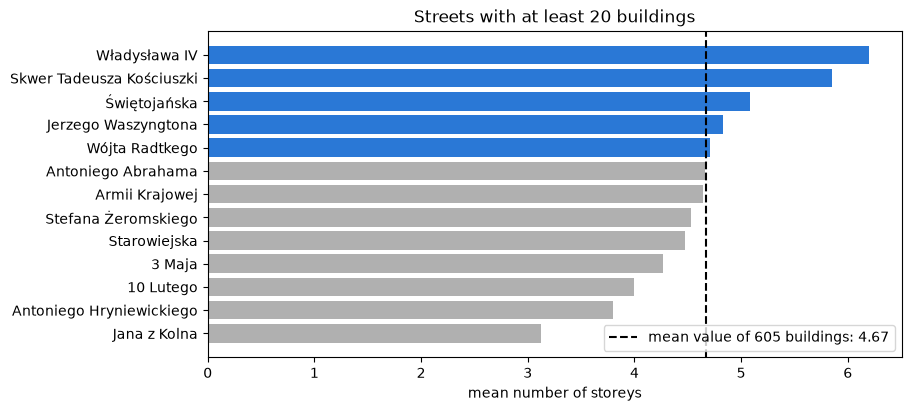

In [20]:
fig6, ax6 = plt.subplots(figsize=(9, 4), layout="constrained")

colors6 = [
    "#2a78d6" if value >= mean6 else "#b0b0b0"
    for value in build_num_streets_rank["num_storeys_mean"]
]

ax6.barh(
    build_num_streets_rank.index,
    build_num_streets_rank["num_storeys_mean"],
    color=colors6,
)
ax6.axvline(
    mean6,
    color="black",
    linestyle="--",
    label=f"mean value of {total_num_build6} buildings: {mean6:.2f}",
)

ax6.legend(loc="lower right")
ax6.set_title("Streets with at least 20 buildings")
ax6.set_xlabel("mean number of storeys")

plt.show()

7.

In [21]:
build_num_streets_perc = (
    data_gdynia.pipe(only_big_streets, min_build=20)
    .groupby(["addr_street", "arch_style"])
    .agg(size=("osm_id", "size"))
    .assign(size_street=lambda d: d.groupby("addr_street").transform("sum"))
    .assign(style_share=lambda d: d["size"] / d["size_street"])
    .reset_index()
)
build_num_modernism_perc = (
    build_num_streets_perc.loc[build_num_streets_perc["arch_style"] == "modernizm"]
    .set_index("addr_street")
    .sort_values("style_share", ascending=True)
)
build_num_modernism_perc

,arch_style,size,size_street,style_share
addr_street,,,,
Jerzego Waszyngtona,modernizm,7,29,0.241379
10 Lutego,modernizm,15,48,0.312500
Antoniego Hryniewickiego,modernizm,10,25,0.400000
Jana z Kolna,modernizm,19,41,0.463415
3 Maja,modernizm,14,26,0.538462
Władysława IV,modernizm,24,41,0.585366
Armii Krajowej,modernizm,23,36,0.638889
Wójta Radtkego,modernizm,29,45,0.644444
Starowiejska,modernizm,39,59,0.661017


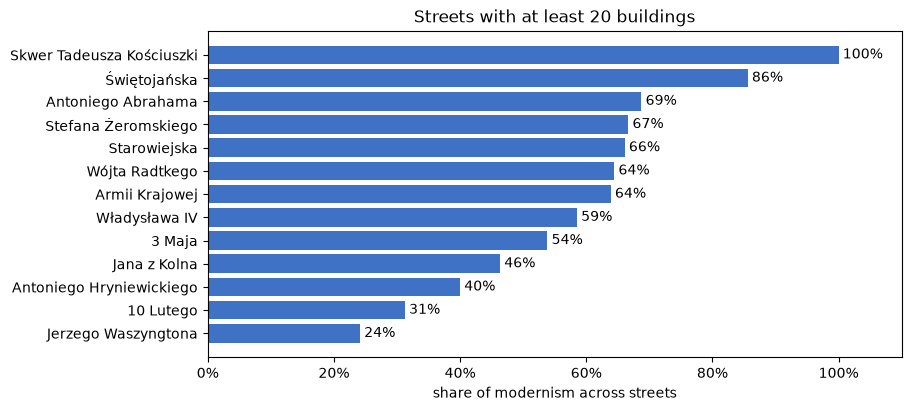

In [ ]:
fig7, ax7 = plt.subplots(figsize=(9, 4), layout="constrained")

bars = ax7.barh(
    build_num_modernism_perc.index,
    build_num_modernism_perc["style_share"],
    color=style_colors["modernizm"],
)

ax7.bar_label(bars, fmt="{:.0%}", padding=3)
ax7.set_title("Streets with at least 20 buildings")
ax7.set_xlabel("share of modernism across streets")
ax7.set_xlim(0, 1.1)
ax7.xaxis.set_major_formatter(PercentFormatter(xmax=1))

plt.show()

8.

In [23]:
build_num_streets_perc_all = (
    data_gdynia.pipe(only_big_streets, min_build=20)
    .groupby(["addr_street", "arch_style"])
    .agg(size=("osm_id", "size"))
    .assign(size_street=lambda d: d.groupby("addr_street").transform("sum"))
    .assign(style_share=lambda d: d["size"] / d["size_street"])
)

In [24]:
build_num_streets_perc_all_unstack = build_num_streets_perc_all["style_share"].unstack(
    fill_value=0
)
build_num_streets_perc_all_unstack = build_num_streets_perc_all_unstack[
    list(style_colors)
].sort_values("modernizm")
build_num_streets_perc_all_unstack

arch_style,modernizm,współczesność,klasycyzm,tradycjonalizm,postmodernizm
addr_street,,,,,
Jerzego Waszyngtona,0.241379,0.551724,0.137931,0.068966,0.000000
10 Lutego,0.312500,0.375000,0.312500,0.000000,0.000000
Antoniego Hryniewickiego,0.400000,0.600000,0.000000,0.000000,0.000000
Jana z Kolna,0.463415,0.536585,0.000000,0.000000,0.000000
3 Maja,0.538462,0.346154,0.115385,0.000000,0.000000
Władysława IV,0.585366,0.341463,0.024390,0.000000,0.048780
Armii Krajowej,0.638889,0.222222,0.111111,0.000000,0.027778
Wójta Radtkego,0.644444,0.244444,0.066667,0.022222,0.022222
Starowiejska,0.661017,0.220339,0.084746,0.033898,0.000000


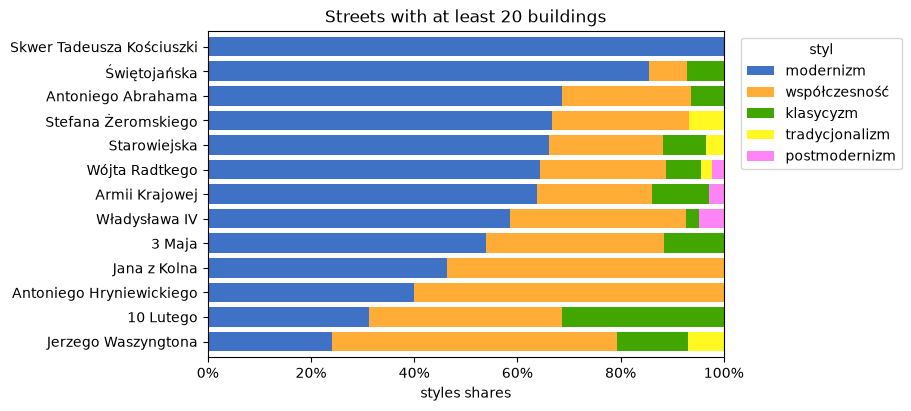

In [ ]:
fig8, ax8 = plt.subplots(figsize=(9, 4), layout="constrained")

build_num_streets_perc_all_unstack.plot.barh(
    stacked=True, ax=ax8, color=style_colors, width=0.8
)

ax8.set_title("Streets with at least 20 buildings")
ax8.set_xlim(0, 1)
ax8.xaxis.set_major_formatter(PercentFormatter(xmax=1))
ax8.legend(title="styl", bbox_to_anchor=(1.02, 1), loc="upper left")
ax8.set_ylabel("")
ax8.set_xlabel("styles shares")

plt.show()

9.

In [ ]:
data_gdynia["num_build_street"] = data_gdynia.groupby("addr_street").transform("size")
data_gdynia["num_build_rank"] = data_gdynia["num_build_street"].rank(
    ascending=False, method="dense"
)
data_gdynia_5_larg_streets = data_gdynia.loc[data_gdynia["num_build_rank"] <= 5]
data_gdynia_5_larg_streets = data_gdynia_5_larg_streets.groupby(
    ["addr_street", "arch_style"]
).agg(num_build=("arch_style", "size"))
data_gdynia_5_larg_streets["rank"] = data_gdynia_5_larg_streets.groupby(
    "addr_street"
).rank(ascending=False, method="min")
data_gdynia_5_larg_streets = data_gdynia_5_larg_streets.loc[
    data_gdynia_5_larg_streets["rank"] <= 2, ["num_build"]
]
data_gdynia_5_larg_streets_styles = data_gdynia_5_larg_streets["num_build"].unstack(
    fill_value=0
)
data_gdynia_5_larg_streets_sns = data_gdynia_5_larg_streets.reset_index()

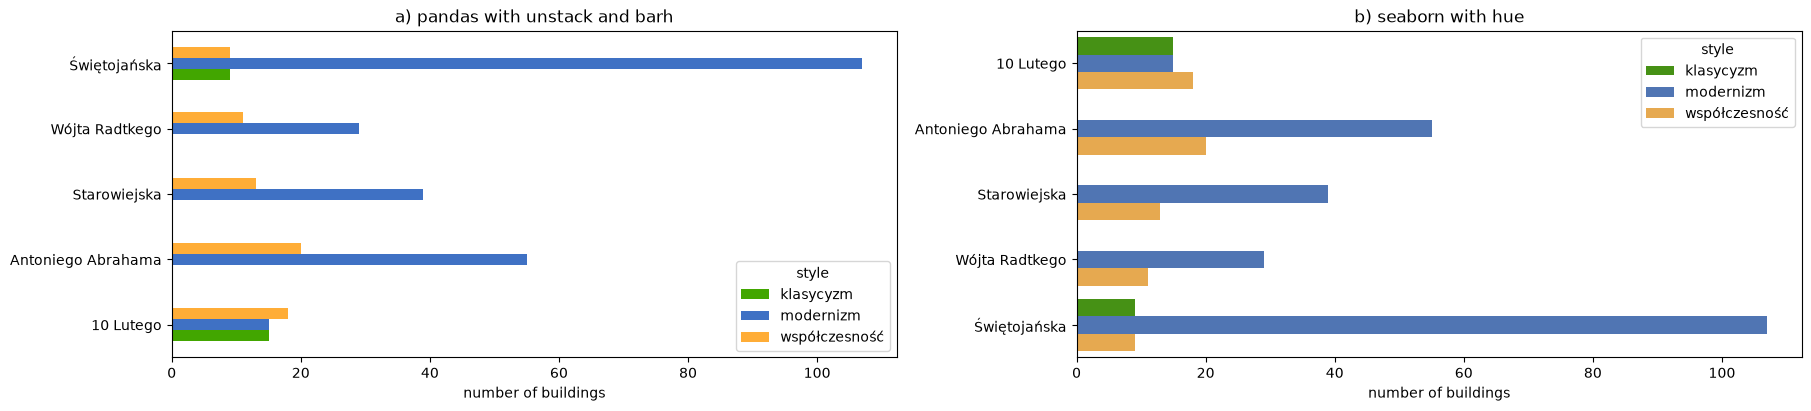

In [ ]:
fig9, ax9 = plt.subplots(1, 2, figsize=(18, 4), layout="constrained")

data_gdynia_5_larg_streets_styles.plot.barh(ax=ax9[0], color=style_colors)
sns.barplot(
    ax=ax9[1],
    x="num_build",
    y="addr_street",
    hue="arch_style",
    data=data_gdynia_5_larg_streets_sns,
    palette=style_colors,
    orient="h",
)


ax9[0].set_title("a) pandas with unstack and barh")
ax9[1].set_title("b) seaborn with hue")


for ax in ax9:
    ax.set_xlabel("number of buildings")
    ax.set_ylabel("")
    ax.legend(title="style")
plt.show()

10.

In [ ]:
data_gdynia_4_larg_streets = data_gdynia.loc[data_gdynia["num_build_rank"] <= 4]
data_gdynia_4_larg_streets_dates = (
    data_gdynia_4_larg_streets.groupby(["addr_street", "build_year_est"])
    .agg(num_build=("osm_id", "size"))
    .assign(sum_street=lambda d: d.groupby("addr_street").transform("sum"))
    .assign(share=lambda d: d["num_build"] / d["sum_street"])
)


data_gdynia_4_larg_streets_dates = data_gdynia_4_larg_streets_dates.loc[
    :, ["num_build", "share"]
].reset_index()
data_gdynia_4_larg_streets_dates

,addr_street,build_year_est,num_build,share
0,10 Lutego,1910,1,0.020833
1,10 Lutego,1920,11,0.229167
2,10 Lutego,1930,12,0.250000
3,10 Lutego,1950,5,0.104167
4,10 Lutego,1960,1,0.020833
5,10 Lutego,1980,5,0.104167
6,10 Lutego,1990,7,0.145833
7,10 Lutego,2000,4,0.083333
8,10 Lutego,2020,2,0.041667
9,Antoniego Abrahama,1920,3,0.037500


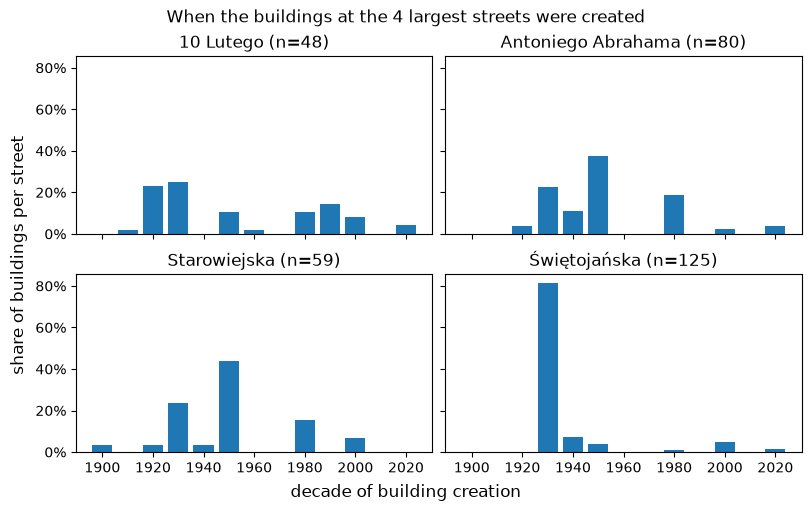

In [ ]:
fig10, ax10 = plt.subplots(
    2, 2, figsize=(8, 5), sharex=True, sharey=True, layout="constrained"
)


for ax, (street, grp) in zip(
    ax10.flat, data_gdynia_4_larg_streets_dates.groupby("addr_street")
):
    ax.bar(grp["build_year_est"], grp["share"], width=8)
    ax.set(title=f"{street} (n={grp['num_build'].sum()})")
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))


fig10.suptitle("When the buildings at the 4 largest streets were created")
fig10.supxlabel("decade of building creation")
fig10.supylabel("share of buildings per street")

plt.show()
